# Content-Based Movie Recommendation System

**BCA Data Science & Analysis project — beginner-friendly notebook**

This notebook follows the supplied student guide. It builds a content-based recommender from the TMDB 5000 Movies dataset. It also explores the dataset with ten labelled charts.

> **Important for your internship report:** Run this notebook yourself, review the results, and keep screenshots of the outputs you understand. Do not claim this project was completed during the June–July internship if you complete it later. You can describe it accurately as an additional/independent project if that is the case.

## What the project will do

1. Load the movie and credits CSV files and combine them.
2. Inspect and clean the dataset.
3. Create ten exploratory data analysis (EDA) charts.
4. Combine each movie's genre, keywords, cast, director, and overview into text tags.
5. Turn the tags into numeric vectors with `CountVectorizer`.
6. Calculate similarity with cosine similarity.
7. Recommend up to ten movies with content similar to a movie title you enter.

**Tools:** Python, Jupyter Notebook, NumPy, Pandas, Matplotlib, Seaborn, and scikit-learn.

## Step 0 — Set up the files

Download the **TMDB 5000 Movie Dataset** from Kaggle. Put these two CSV files in the same folder as this notebook:

- `tmdb_5000_movies.csv` — rename to `movies.csv`
- `tmdb_5000_credits.csv` — rename to `credits.csv`

Folder example:

```text
MovieRecommendationProject/
├── Movie_Recommendation_System_Beginner.ipynb
├── movies.csv
└── credits.csv
```

The CSVs are not included in this notebook, so you need to download them separately. In Jupyter Notebook, run the following installation cell once if any library is missing.

In [2]:
%pip install numpy pandas matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


## Step 1 — Import the libraries

Libraries are ready-made code packages. We use Pandas for tables, Matplotlib/Seaborn for graphs, and scikit-learn for turning text into vectors and measuring similarity.

In [3]:
from pathlib import Path
import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
print("Libraries imported successfully.")

Libraries imported successfully.


## Step 2 — Load the datasets

The two CSV files contain movie details and credits. This cell shows a helpful message if the files are not in the notebook folder.

In [4]:
movies_path = Path("movies.csv")
credits_path = Path("credits.csv")

if not movies_path.exists() or not credits_path.exists():
    raise FileNotFoundError(
        "CSV files not found. Put movies.csv and credits.csv in the same folder as this notebook."
    )

movies_raw = pd.read_csv(movies_path)
credits_raw = pd.read_csv(credits_path)

print("Movies dataset shape:", movies_raw.shape)
print("Credits dataset shape:", credits_raw.shape)
display(movies_raw.head())
display(credits_raw.head())

Movies dataset shape: (4803, 20)
Credits dataset shape: (4803, 4)


,budget,genres,homepage,id,keywords,original_language,original_title,overview,popularity,production_companies,production_countries,release_date,revenue,runtime,spoken_languages,status,tagline,title,vote_average,vote_count
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.avatarmovie.com/,19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...",en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.437577,"[{""name"": ""Ingenious Film Partners"", ""id"": 289...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2009-12-10,2787965087,162.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,Enter the World of Pandora.,Avatar,7.2,11800
1,300000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...",http://disney.go.com/disneypictures/pirates/,285,"[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",139.082615,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2007-05-19,961000000,169.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500
2,245000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.sonypictures.com/movies/spectre/,206647,"[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...",en,Spectre,A cryptic message from Bond’s past sends him o...,107.376788,"[{""name"": ""Columbia Pictures"", ""id"": 5}, {""nam...","[{""iso_3166_1"": ""GB"", ""name"": ""United Kingdom""...",2015-10-26,880674609,148.0,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""},...",Released,A Plan No One Escapes,Spectre,6.3,4466
3,250000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 80, ""nam...",http://www.thedarkknightrises.com/,49026,"[{""id"": 849, ""name"": ""dc comics""}, {""id"": 853,...",en,The Dark Knight Rises,Following the death of District Attorney Harve...,112.312950,"[{""name"": ""Legendary Pictures"", ""id"": 923}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2012-07-16,1084939099,165.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,The Legend Ends,The Dark Knight Rises,7.6,9106
4,260000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://movies.disney.com/john-carter,49529,"[{""id"": 818, ""name"": ""based on novel""}, {""id"":...",en,John Carter,"John Carter is a war-weary, former military ca...",43.926995,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}]","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2012-03-07,284139100,132.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"Lost in our world, found in another.",John Carter,6.1,2124


,movie_id,title,cast,crew
0,19995,Avatar,"[{""cast_id"": 242, ""character"": ""Jake Sully"", ""...","[{""credit_id"": ""52fe48009251416c750aca23"", ""de..."
1,285,Pirates of the Caribbean: At World's End,"[{""cast_id"": 4, ""character"": ""Captain Jack Spa...","[{""credit_id"": ""52fe4232c3a36847f800b579"", ""de..."
2,206647,Spectre,"[{""cast_id"": 1, ""character"": ""James Bond"", ""cr...","[{""credit_id"": ""54805967c3a36829b5002c41"", ""de..."
3,49026,The Dark Knight Rises,"[{""cast_id"": 2, ""character"": ""Bruce Wayne / Ba...","[{""credit_id"": ""52fe4781c3a36847f81398c3"", ""de..."
4,49529,John Carter,"[{""cast_id"": 5, ""character"": ""John Carter"", ""c...","[{""credit_id"": ""52fe479ac3a36847f813eaa3"", ""de..."


## Step 3 — Merge the datasets

Both files have a `title` column. We merge them so each movie record can contain movie details as well as cast and crew information.

In [5]:
required_movie_columns = {"title", "overview", "genres", "keywords", "release_date", "runtime", "budget", "revenue", "vote_average", "vote_count", "popularity", "original_language", "production_companies"}
required_credit_columns = {"title", "cast", "crew"}

missing_movie_columns = required_movie_columns - set(movies_raw.columns)
missing_credit_columns = required_credit_columns - set(credits_raw.columns)
if missing_movie_columns or missing_credit_columns:
    raise ValueError(
        f"Unexpected CSV columns. Missing from movies.csv: {sorted(missing_movie_columns)}; "
        f"missing from credits.csv: {sorted(missing_credit_columns)}"
    )

movies = movies_raw.merge(credits_raw, on="title", how="left", suffixes=("", "_credits"))
print("Merged dataset shape:", movies.shape)
display(movies[["title", "overview", "genres", "cast", "crew"]].head(3))

Merged dataset shape: (4809, 23)


,title,overview,genres,cast,crew
0,Avatar,"In the 22nd century, a paraplegic Marine is di...","[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...","[{""cast_id"": 242, ""character"": ""Jake Sully"", ""...","[{""credit_id"": ""52fe48009251416c750aca23"", ""de..."
1,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...","[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...","[{""cast_id"": 4, ""character"": ""Captain Jack Spa...","[{""credit_id"": ""52fe4232c3a36847f800b579"", ""de..."
2,Spectre,A cryptic message from Bond’s past sends him o...,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...","[{""cast_id"": 1, ""character"": ""James Bond"", ""cr...","[{""credit_id"": ""54805967c3a36829b5002c41"", ""de..."


## Step 4 — Explore the raw data

Before cleaning, check the number of rows, column types, and missing values. This helps us understand what needs attention.

In [6]:
movies.info()
print("\nMissing values in the 10 columns with the most missing data:")
display(movies.isnull().sum().sort_values(ascending=False).head(10).to_frame("missing_count"))
print("\nNumeric summary:")
display(movies.describe(include="number").T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4809 entries, 0 to 4808
Data columns (total 23 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   budget                4809 non-null   int64  
 1   genres                4809 non-null   object 
 2   homepage              1713 non-null   object 
 3   id                    4809 non-null   int64  
 4   keywords              4809 non-null   object 
 5   original_language     4809 non-null   object 
 6   original_title        4809 non-null   object 
 7   overview              4806 non-null   object 
 8   popularity            4809 non-null   float64
 9   production_companies  4809 non-null   object 
 10  production_countries  4809 non-null   object 
 11  release_date          4808 non-null   object 
 12  revenue               4809 non-null   int64  
 13  runtime               4807 non-null   float64
 14  spoken_languages      4809 non-null   object 
 15  status               

,missing_count
homepage,3096
tagline,844
overview,3
runtime,2
release_date,1
cast,0
movie_id,0
vote_count,0
vote_average,0
title,0



Numeric summary:


,count,mean,std,min,25%,50%,75%,max
budget,4809.0,2.902780e+07,4.070473e+07,0.0,780000.00000,1.500000e+07,4.000000e+07,3.800000e+08
id,4809.0,5.712057e+04,8.865337e+04,5.0,9012.00000,1.462400e+04,5.859500e+04,4.594880e+05
popularity,4809.0,2.149166e+01,3.180337e+01,0.0,4.66723,1.292159e+01,2.835053e+01,8.755813e+02
revenue,4809.0,8.227511e+07,1.628379e+08,0.0,0.00000,1.917000e+07,9.291317e+07,2.787965e+09
runtime,4807.0,1.068823e+02,2.260254e+01,0.0,94.00000,1.030000e+02,1.180000e+02,3.380000e+02
vote_average,4809.0,6.092514e+00,1.193989e+00,0.0,5.60000,6.200000e+00,6.800000e+00,1.000000e+01
vote_count,4809.0,6.903317e+02,1.234187e+03,0.0,54.00000,2.350000e+02,7.370000e+02,1.375200e+04
movie_id,4809.0,5.712057e+04,8.865337e+04,5.0,9012.00000,1.462400e+04,5.859500e+04,4.594880e+05


## Step 5 — Clean important fields

- Rows with no movie overview are removed because the overview is part of the recommendation text.
- Duplicate movie titles are removed so the same movie is not listed repeatedly.
- Dates, runtime, budget, and revenue are converted to useful types.
- A budget or revenue of zero is treated as unknown for charting, rather than as a meaningful real-world value.

In [7]:
movies = movies.dropna(subset=["overview"]).copy()
movies["overview"] = movies["overview"].astype(str)
movies = movies.drop_duplicates(subset=["title"]).reset_index(drop=True)

movies["release_date"] = pd.to_datetime(movies["release_date"], errors="coerce")
movies["release_year"] = movies["release_date"].dt.year

for column in ["runtime", "budget", "revenue", "vote_average", "vote_count", "popularity"]:
    movies[column] = pd.to_numeric(movies[column], errors="coerce")

movies["budget"] = movies["budget"].replace(0, np.nan)
movies["revenue"] = movies["revenue"].replace(0, np.nan)

print("Cleaned dataset shape:", movies.shape)
print("Missing overview values:", movies["overview"].isna().sum())
print("Duplicate titles:", movies["title"].duplicated().sum())
display(movies[["title", "release_year", "runtime", "budget", "revenue"]].head())

Cleaned dataset shape: (4797, 24)
Missing overview values: 0
Duplicate titles: 0


,title,release_year,runtime,budget,revenue
0,Avatar,2009.0,162.0,237000000.0,2.787965e+09
1,Pirates of the Caribbean: At World's End,2007.0,169.0,300000000.0,9.610000e+08
2,Spectre,2015.0,148.0,245000000.0,8.806746e+08
3,The Dark Knight Rises,2012.0,165.0,250000000.0,1.084939e+09
4,John Carter,2012.0,132.0,260000000.0,2.841391e+08


## Step 6 — Parse the list-like columns

Some columns contain text that represents a list of dictionaries. `ast.literal_eval()` safely converts that text into Python data structures. The helper below returns an empty list if a value cannot be parsed.

In [8]:
def parse_names(value, key="name"):
    """Extract names from a string containing a list of dictionaries."""
    if not isinstance(value, str) or not value.strip():
        return []
    try:
        items = ast.literal_eval(value)
        if not isinstance(items, list):
            return []
        return [item.get(key, "") for item in items if isinstance(item, dict) and item.get(key)]
    except (ValueError, SyntaxError, TypeError):
        return []


def get_top_cast(cast_value, top_n=3):
    """Return names of up to the first three cast members."""
    if not isinstance(cast_value, str) or not cast_value.strip():
        return []
    try:
        cast_items = ast.literal_eval(cast_value)
        return [person.get("name", "") for person in cast_items[:top_n]
                if isinstance(person, dict) and person.get("name")]
    except (ValueError, SyntaxError, TypeError):
        return []


def get_director(crew_value):
    """Return the director's name as a list, if available."""
    if not isinstance(crew_value, str) or not crew_value.strip():
        return []
    try:
        crew_items = ast.literal_eval(crew_value)
        for person in crew_items:
            if isinstance(person, dict) and person.get("job") == "Director" and person.get("name"):
                return [person["name"]]
    except (ValueError, SyntaxError, TypeError):
        pass
    return []

movies["genres_list"] = movies["genres"].apply(parse_names)
movies["keywords_list"] = movies["keywords"].apply(parse_names)
movies["cast_list"] = movies["cast"].apply(get_top_cast)
movies["director_list"] = movies["crew"].apply(get_director)
movies["production_companies_list"] = movies["production_companies"].apply(parse_names)
movies["overview_list"] = movies["overview"].apply(lambda value: str(value).split())

display(movies[["title", "genres_list", "keywords_list", "cast_list", "director_list"]].head(3))

,title,genres_list,keywords_list,cast_list,director_list
0,Avatar,"[Action, Adventure, Fantasy, Science Fiction]","[culture clash, future, space war, space colon...","[Sam Worthington, Zoe Saldana, Sigourney Weaver]",[James Cameron]
1,Pirates of the Caribbean: At World's End,"[Adventure, Fantasy, Action]","[ocean, drug abuse, exotic island, east india ...","[Johnny Depp, Orlando Bloom, Keira Knightley]",[Gore Verbinski]
2,Spectre,"[Action, Adventure, Crime]","[spy, based on novel, secret agent, sequel, mi...","[Daniel Craig, Christoph Waltz, Léa Seydoux]",[Sam Mendes]


# Exploratory Data Analysis (EDA)

These ten charts help us understand the dataset. Each chart has a title and labelled axes. The charts describe the dataset supplied with the project; results can vary if a different dataset version is used.

## Chart 1 — Genre distribution

This chart counts how often each genre appears. A movie can belong to more than one genre.

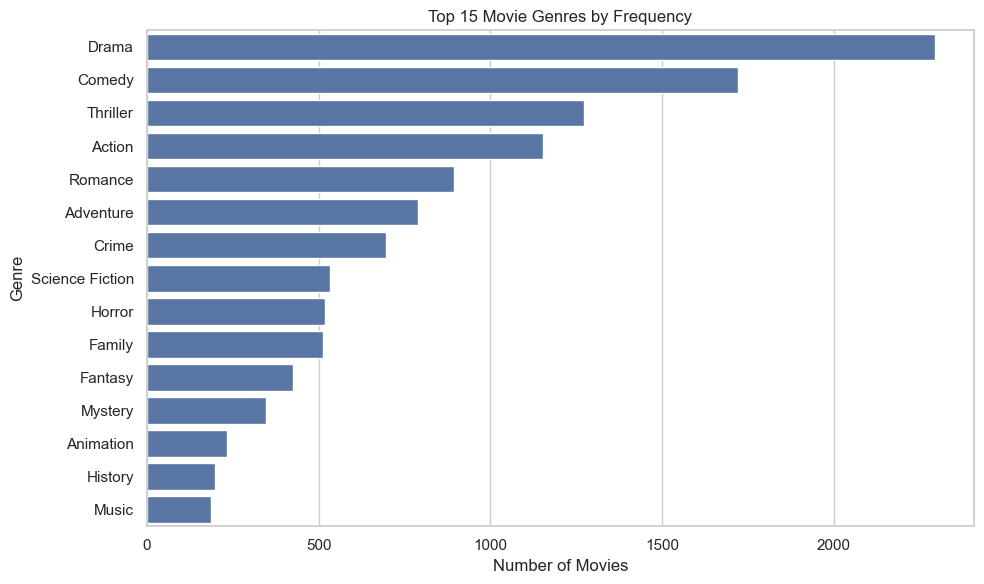

In [9]:
genre_counts = movies["genres_list"].explode().dropna().value_counts().head(15)
plt.figure(figsize=(10, 6))
sns.barplot(x=genre_counts.values, y=genre_counts.index)
plt.title("Top 15 Movie Genres by Frequency")
plt.xlabel("Number of Movies")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

## Chart 2 — Top-rated movies

We filter for movies with a reasonable number of votes before sorting by rating. This reduces the chance that a movie with only a few votes ranks unusually high.

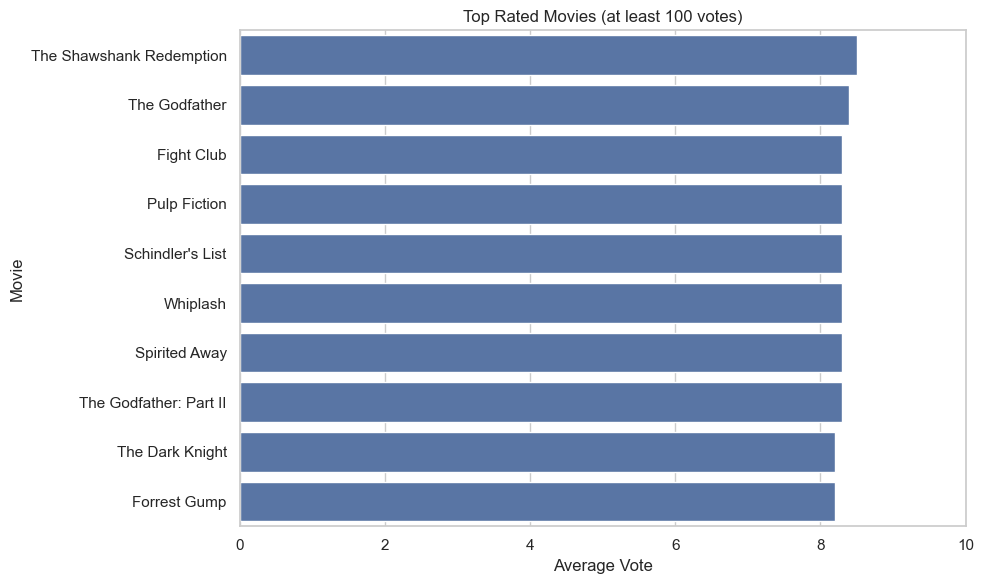

,title,vote_average,vote_count
1881,The Shawshank Redemption,8.5,8205
3335,The Godfather,8.4,5893
662,Fight Club,8.3,9413
3230,Pulp Fiction,8.3,8428
1818,Schindler's List,8.3,4329
3862,Whiplash,8.3,4254
2294,Spirited Away,8.3,3840
2730,The Godfather: Part II,8.3,3338
65,The Dark Knight,8.2,12002
809,Forrest Gump,8.2,7927


In [10]:
min_votes = 100
top_rated = movies.loc[movies["vote_count"] >= min_votes, ["title", "vote_average", "vote_count"]]
top_rated = top_rated.dropna().sort_values(["vote_average", "vote_count"], ascending=False).head(10)
if top_rated.empty:
    print("No movies met the vote-count threshold; try lowering min_votes.")
else:
    plt.figure(figsize=(10, 6))
    sns.barplot(data=top_rated, x="vote_average", y="title")
    plt.title(f"Top Rated Movies (at least {min_votes} votes)")
    plt.xlabel("Average Vote")
    plt.ylabel("Movie")
    plt.xlim(0, 10)
    plt.tight_layout()
    plt.show()
    display(top_rated)

## Chart 3 — Most popular movies

The `popularity` column is used here as the dataset's popularity measure; it is not the same as the audience rating.

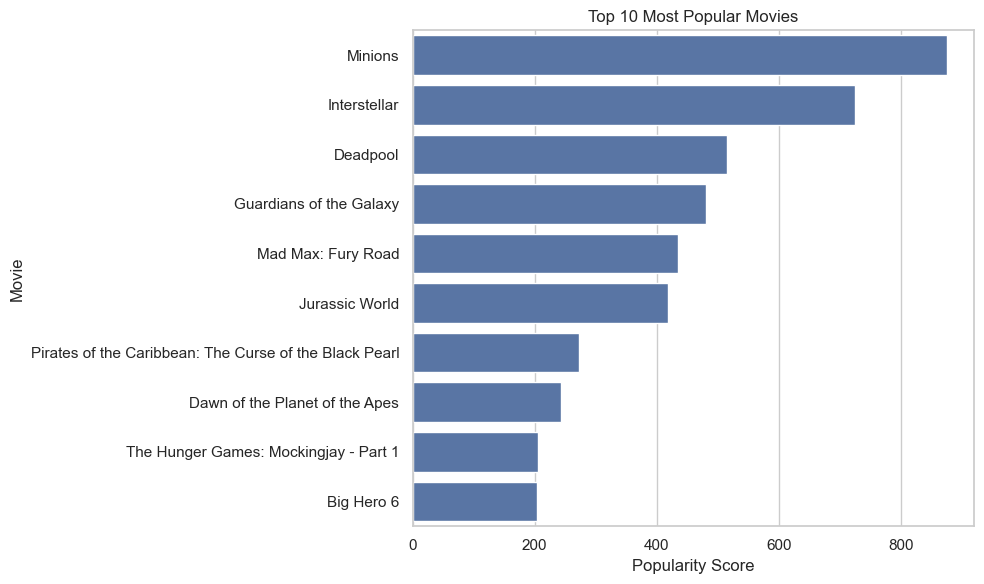

,title,popularity
546,Minions,875.581305
95,Interstellar,724.247784
788,Deadpool,514.569956
94,Guardians of the Galaxy,481.098624
127,Mad Max: Fury Road,434.278564
28,Jurassic World,418.708552
199,Pirates of the Caribbean: The Curse of the Bla...,271.972889
82,Dawn of the Planet of the Apes,243.791743
200,The Hunger Games: Mockingjay - Part 1,206.227151
88,Big Hero 6,203.734590


In [11]:
top_popular = movies.dropna(subset=["popularity"]).nlargest(10, "popularity")[["title", "popularity"]]
plt.figure(figsize=(10, 6))
sns.barplot(data=top_popular, x="popularity", y="title")
plt.title("Top 10 Most Popular Movies")
plt.xlabel("Popularity Score")
plt.ylabel("Movie")
plt.tight_layout()
plt.show()
display(top_popular)

## Chart 4 — Runtime distribution

A histogram shows how movie runtimes are spread across the dataset.

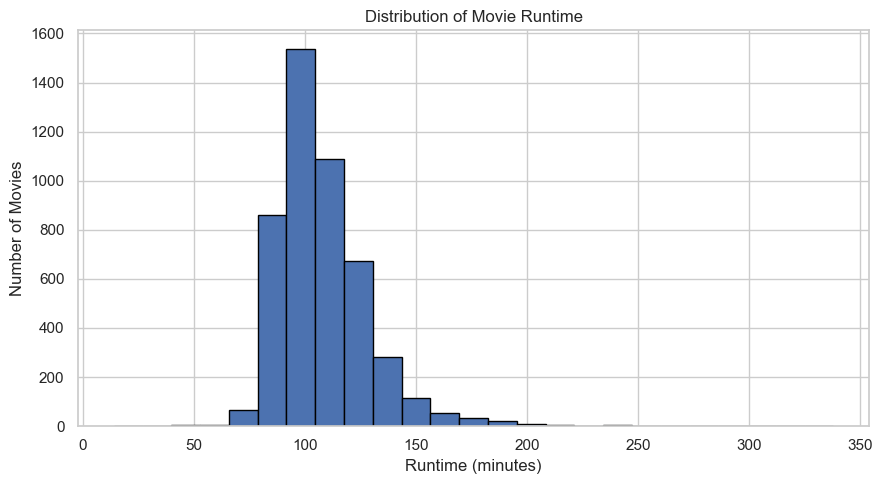

In [12]:
runtime_data = movies.loc[movies["runtime"].between(1, 400), "runtime"].dropna()
plt.figure(figsize=(9, 5))
plt.hist(runtime_data, bins=25, edgecolor="black")
plt.title("Distribution of Movie Runtime")
plt.xlabel("Runtime (minutes)")
plt.ylabel("Number of Movies")
plt.tight_layout()
plt.show()

## Chart 5 — Budget versus revenue

This scatter plot uses only rows with positive budget and revenue. Logarithmic axes help show values that differ greatly in size. It does not prove that a larger budget causes higher revenue.

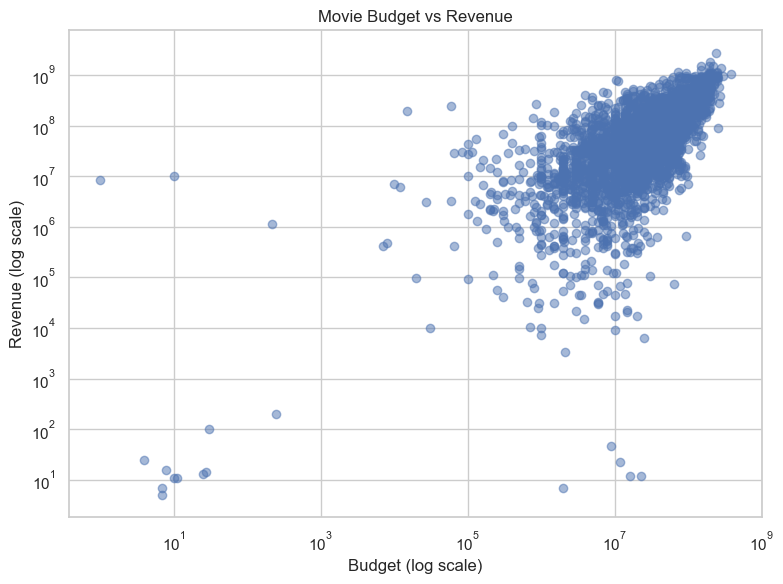

Movies plotted: 3228


In [13]:
budget_revenue = movies.dropna(subset=["budget", "revenue"])
budget_revenue = budget_revenue.loc[(budget_revenue["budget"] > 0) & (budget_revenue["revenue"] > 0)]
plt.figure(figsize=(8, 6))
plt.scatter(budget_revenue["budget"], budget_revenue["revenue"], alpha=0.5)
plt.xscale("log")
plt.yscale("log")
plt.title("Movie Budget vs Revenue")
plt.xlabel("Budget (log scale)")
plt.ylabel("Revenue (log scale)")
plt.tight_layout()
plt.show()
print("Movies plotted:", len(budget_revenue))

## Chart 6 — Correlation heatmap

Correlation describes how two numeric columns move together in this dataset. It does not establish cause and effect.

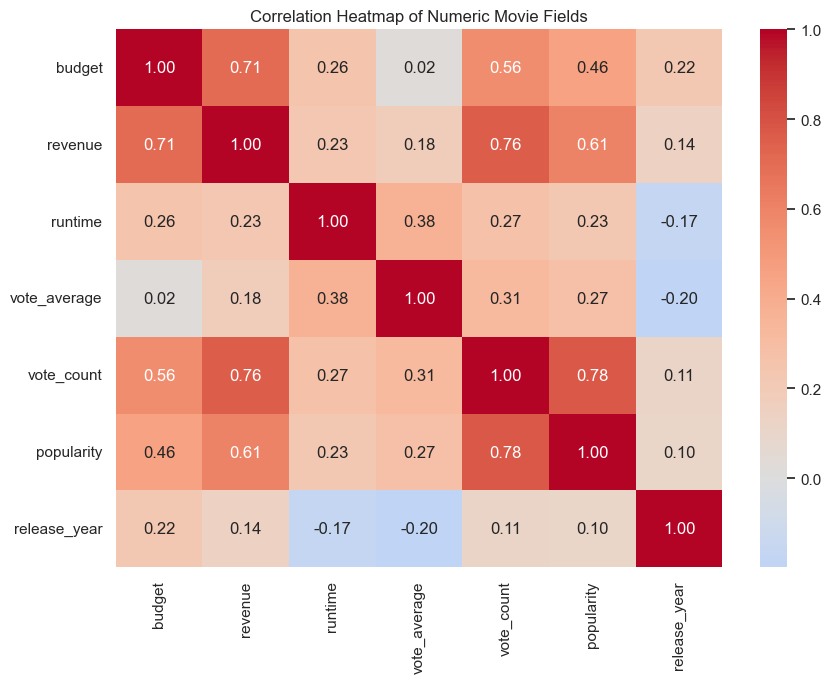

In [14]:
numeric_columns = ["budget", "revenue", "runtime", "vote_average", "vote_count", "popularity", "release_year"]
correlation = movies[numeric_columns].corr(numeric_only=True)
plt.figure(figsize=(9, 7))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap of Numeric Movie Fields")
plt.tight_layout()
plt.show()

## Chart 7 — Average vote distribution

This histogram shows how average ratings are distributed among movies with a valid rating.

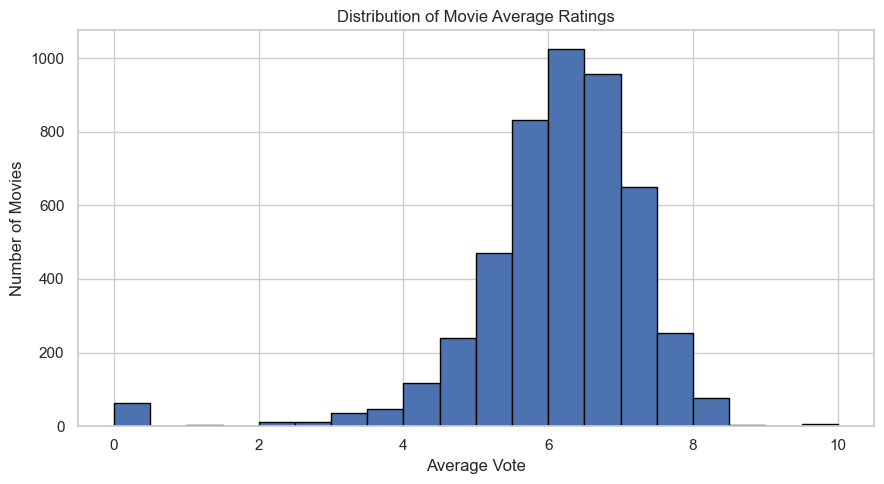

In [15]:
vote_data = movies["vote_average"].dropna()
plt.figure(figsize=(9, 5))
plt.hist(vote_data, bins=20, edgecolor="black")
plt.title("Distribution of Movie Average Ratings")
plt.xlabel("Average Vote")
plt.ylabel("Number of Movies")
plt.tight_layout()
plt.show()

## Chart 8 — Movies released by year

This chart counts how many movies in this dataset were released in each year. Years with missing or invalid dates are excluded.

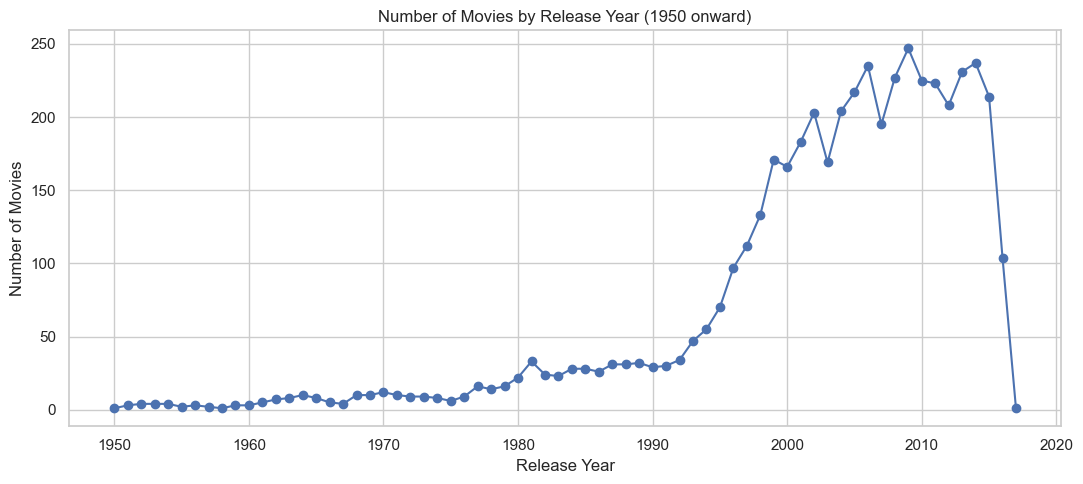

In [16]:
year_counts = movies["release_year"].dropna().astype(int).value_counts().sort_index()
year_counts = year_counts.loc[year_counts.index >= 1950]
plt.figure(figsize=(11, 5))
plt.plot(year_counts.index, year_counts.values, marker="o", linewidth=1.5)
plt.title("Number of Movies by Release Year (1950 onward)")
plt.xlabel("Release Year")
plt.ylabel("Number of Movies")
plt.tight_layout()
plt.show()

## Chart 9 — Top production companies

A movie can have several production companies, so each company is counted wherever it appears.

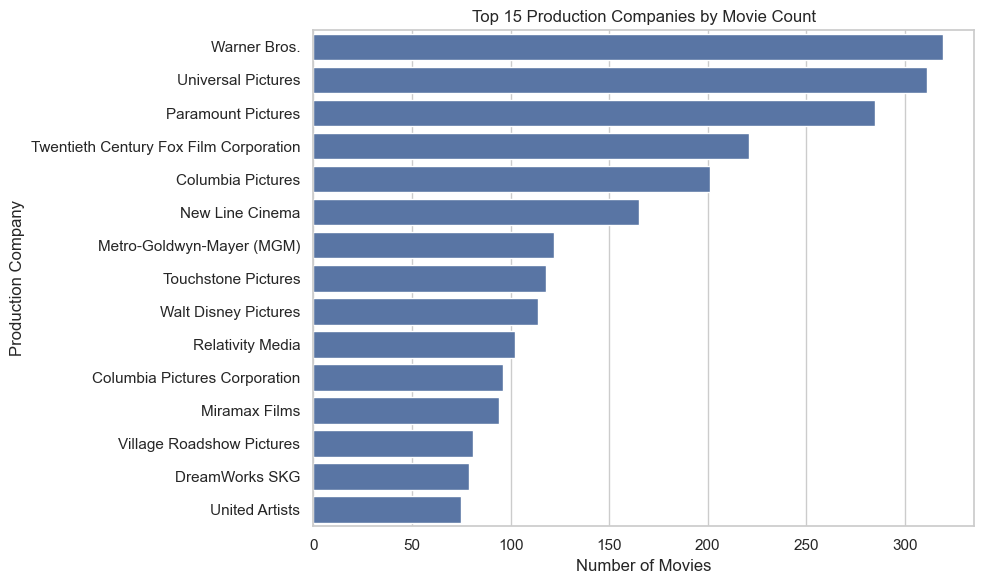

In [17]:
company_counts = movies["production_companies_list"].explode().dropna().value_counts().head(15)
plt.figure(figsize=(10, 6))
sns.barplot(x=company_counts.values, y=company_counts.index)
plt.title("Top 15 Production Companies by Movie Count")
plt.xlabel("Number of Movies")
plt.ylabel("Production Company")
plt.tight_layout()
plt.show()

## Chart 10 — Original language distribution

This chart counts the ten most common original-language codes in the dataset.

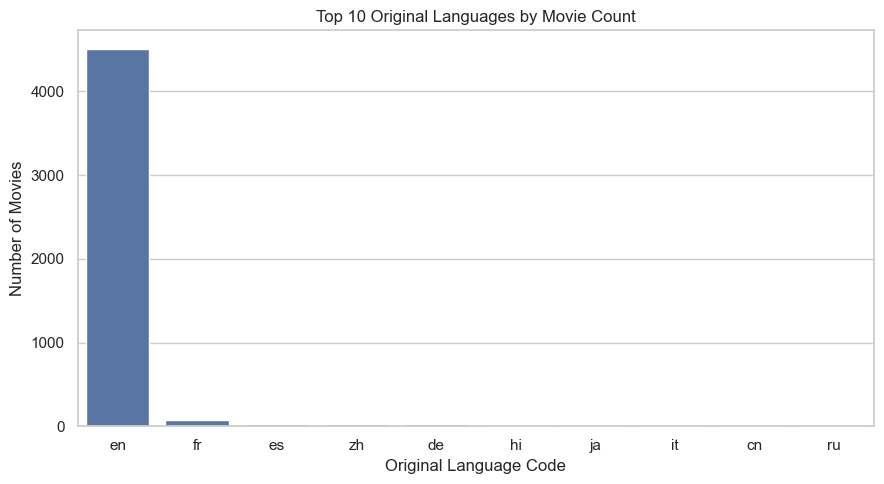

,movie_count
original_language,
en,4502
fr,70
es,32
zh,27
de,26
hi,19
ja,16
it,13
cn,12


In [18]:
language_counts = movies["original_language"].dropna().value_counts().head(10)
plt.figure(figsize=(9, 5))
sns.barplot(x=language_counts.index, y=language_counts.values)
plt.title("Top 10 Original Languages by Movie Count")
plt.xlabel("Original Language Code")
plt.ylabel("Number of Movies")
plt.tight_layout()
plt.show()
display(language_counts.to_frame("movie_count"))

# Build the Movie Recommendation System

## Step 7 — Create movie tags

A content-based recommender compares movie descriptions. For each movie, we combine its genres, keywords, top three cast members, director, and overview into one text field called `tags`. The system then looks for movies with similar text content.

In [19]:
def clean_tokens(tokens):
    """Lowercase tokens and remove spaces inside multi-word names."""
    return [str(token).lower().replace(" ", "") for token in tokens if str(token).strip()]

movies["genres_clean"] = movies["genres_list"].apply(clean_tokens)
movies["keywords_clean"] = movies["keywords_list"].apply(clean_tokens)
movies["cast_clean"] = movies["cast_list"].apply(clean_tokens)
movies["director_clean"] = movies["director_list"].apply(clean_tokens)
movies["overview_clean"] = movies["overview_list"].apply(lambda words: [word.lower() for word in words])

movies["tags"] = (
    movies["genres_clean"]
    + movies["keywords_clean"]
    + movies["cast_clean"]
    + movies["director_clean"]
    + movies["overview_clean"]
).apply(lambda tokens: " ".join(tokens))

print("Example movie:", movies.loc[0, "title"])
print("First 300 characters of its tags:")
print(movies.loc[0, "tags"][:300])

Example movie: Avatar
First 300 characters of its tags:
action adventure fantasy sciencefiction cultureclash future spacewar spacecolony society spacetravel futuristic romance space alien tribe alienplanet cgi marine soldier battle loveaffair antiwar powerrelations mindandsoul 3d samworthington zoesaldana sigourneyweaver jamescameron in the 22nd century,


## Step 8 — Convert text into numeric vectors

`CountVectorizer` converts words into numeric features. It ignores common English filler words and keeps up to 5,000 vocabulary terms. The result is stored as a sparse matrix to use memory more efficiently.

In [20]:
new_df = movies[["id", "title", "tags"]].rename(columns={"id": "movie_id"}).reset_index(drop=True)

vectorizer = CountVectorizer(max_features=5000, stop_words="english")
vectors = vectorizer.fit_transform(new_df["tags"].fillna(""))

print("Vector matrix shape:", vectors.shape)
print("Vocabulary size:", len(vectorizer.get_feature_names_out()))
print("First 30 vocabulary terms:", vectorizer.get_feature_names_out()[:30])

Vector matrix shape: (4797, 5000)
Vocabulary size: 5000
First 30 vocabulary terms: ['000' '007' '10' '100' '11' '12' '13' '14' '15' '16' '17' '17th' '18'
 '18th' '19' '1930s' '1940s' '1950s' '1960s' '1970s' '1980' '1980s' '1985'
 '1990s' '19th' '19thcentury' '20' '200' '2009' '20th']


## Step 9 — Calculate cosine similarity

Cosine similarity compares the direction of two movie vectors. A score closer to `1` means their text features are more similar; a score closer to `0` means they have less in common in this representation.

In [21]:
similarity = cosine_similarity(vectors)
print("Similarity matrix shape:", similarity.shape)
print("Example similarity scores:", similarity[0][:5])
print("Are movies perfectly similar to themselves?", np.allclose(np.diag(similarity), 1.0))

Similarity matrix shape: (4797, 4797)
Example similarity scores: [1.         0.08838835 0.05892557 0.03928371 0.18220272]
Are movies perfectly similar to themselves? True


## Step 10 — Create the recommendation function

The function looks for an exact movie title without worrying about uppercase/lowercase letters, ranks other movies by similarity, and returns the top recommendations. If the title is not found, it shows a friendly message instead of crashing.

In [26]:
def recommend(movie_name, n=10):
    """Print and return up to n movies similar to the supplied title."""
    if not isinstance(movie_name, str) or not movie_name.strip():
        print("Please enter a movie title.")
        return []

    matches = new_df[new_df["title"].str.casefold() == movie_name.strip().casefold()]
    if matches.empty:
        print(f"Movie '{movie_name}' was not found. Check the spelling or use a title in the dataset.")
        return []

    idx = matches.index[0]
    distances = list(enumerate(similarity[idx]))
    ranked = sorted(distances, key=lambda pair: pair[1], reverse=True)
    ranked = [(i, score) for i, score in ranked if i != idx][:n]

    results = []
    print(f"Movies similar to {new_df.loc[idx, 'title']}:")
    for movie_index, score in ranked:
        title = new_df.loc[movie_index, "title"]
        print(f"- {title} (similarity: {score:.3f})")
        results.append({"title": title, "similarity": round(float(score), 3)})
    return results

## Step 11 — Test the recommender

Try several genres and titles. The exact results are determined by the dataset and the content features we selected.

In [25]:
for test_title in ["Avatar", "The Godfather", "Toy Story", "Titanic", "Iron Man"]:
    print("\n" + "=" * 50)
    recommend(test_title, n=10)


Movies similar to Avatar:
- Titan A.E. (similarity: 0.257)
- Small Soldiers (similarity: 0.255)
- Independence Day (similarity: 0.249)
- Aliens vs Predator: Requiem (similarity: 0.245)
- Ender's Game (similarity: 0.243)
- Battle: Los Angeles (similarity: 0.241)
- Predators (similarity: 0.240)
- Lifeforce (similarity: 0.240)
- Falcon Rising (similarity: 0.236)
- Krull (similarity: 0.231)

Movies similar to The Godfather:
- The Godfather: Part II (similarity: 0.429)
- Blood Ties (similarity: 0.305)
- Easy Money (similarity: 0.305)
- Mi America (similarity: 0.302)
- The Godfather: Part III (similarity: 0.294)
- Amidst the Devil's Wings (similarity: 0.286)
- Deadfall (similarity: 0.282)
- Nine Queens (similarity: 0.277)
- Road to Perdition (similarity: 0.256)
- The Replacement Killers (similarity: 0.252)

Movies similar to Toy Story:
- Toy Story 2 (similarity: 0.477)
- Toy Story 3 (similarity: 0.449)
- The 40 Year Old Virgin (similarity: 0.308)
- Heartbeeps (similarity: 0.183)
- Max Keebl

### Test invalid input

A robust function should handle an unknown title without stopping the notebook.

In [24]:
recommend("A Movie That Does Not Exist")

Movie 'A Movie That Does Not Exist' was not found. Check the spelling or use a title in the dataset.


[]

## Step 12 — Reflect on the results

Answer these questions in your own words after running the notebook:

1. What types of information are combined into the `tags` field?
2. Why does the system use `CountVectorizer`?
3. What does a higher cosine similarity score mean?
4. Which movies did you test, and were the recommendations sensible?
5. What limitations did you notice? For example, the system mainly uses content information and does not learn each user's personal taste.

**Possible improvement:** Later, you could compare the current approach with `TfidfVectorizer` or build a simple interface. Only report an extension as completed if you actually implement and test it.

## Project checklist

- [ ] Both CSV files load successfully.
- [ ] The movie and credits tables are merged.
- [ ] Missing overviews and duplicate titles are handled.
- [ ] All ten charts display titles and labelled axes.
- [ ] The `tags` field combines genres, keywords, cast, director, and overview.
- [ ] `CountVectorizer` creates numeric vectors.
- [ ] Cosine similarity is calculated.
- [ ] The `recommend()` function returns up to ten recommendations.
- [ ] Several valid titles and at least one invalid title are tested.
- [ ] I can explain the main code sections in my own words.
- [ ] I save screenshots of genuine outputs for the project evidence section.

### Suggested report evidence

After you run the notebook, capture: (1) a few representative EDA charts, (2) the printed vector/similarity checks, and (3) the output from `recommend("Inception")` or another movie in your dataset. Use captions that match the screenshots you actually include.

In [29]:
recommend("Inception")

Movies similar to Inception:
- Duplex (similarity: 0.221)
- The Helix... Loaded (similarity: 0.204)
- Star Trek II: The Wrath of Khan (similarity: 0.201)
- Timecop (similarity: 0.198)
- Chicago Overcoat (similarity: 0.196)
- Looper (similarity: 0.186)
- Premium Rush (similarity: 0.183)
- Cypher (similarity: 0.182)
- Transformers: Revenge of the Fallen (similarity: 0.180)
- Congo (similarity: 0.180)


[{'title': 'Duplex', 'similarity': 0.221},
 {'title': 'The Helix... Loaded', 'similarity': 0.204},
 {'title': 'Star Trek II: The Wrath of Khan', 'similarity': 0.201},
 {'title': 'Timecop', 'similarity': 0.198},
 {'title': 'Chicago Overcoat', 'similarity': 0.196},
 {'title': 'Looper', 'similarity': 0.186},
 {'title': 'Premium Rush', 'similarity': 0.183},
 {'title': 'Cypher', 'similarity': 0.182},
 {'title': 'Transformers: Revenge of the Fallen', 'similarity': 0.18},
 {'title': 'Congo', 'similarity': 0.18}]

In [28]:
recommend("This Movie Does Not Exist")

Movie 'This Movie Does Not Exist' was not found. Check the spelling or use a title in the dataset.


[]